In [18]:
from pathlib import Path

# CHANGE THIS to your actual path
DATA_DIR = Path("../data/NCT-CRC-HE-100K")

for class_dir in sorted(DATA_DIR.iterdir()):
    if class_dir.is_dir():
        n = len(list(class_dir.glob("*.tif")))
        print(class_dir.name, n)

ADI 10407
BACK 10566
DEB 11512
LYM 11557
MUC 8896
MUS 13536
NORM 8763
STR 10446
TUM 14317


Total images: 100000
Classes: ['ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM']
Batch shape: torch.Size([16, 3, 96, 96])


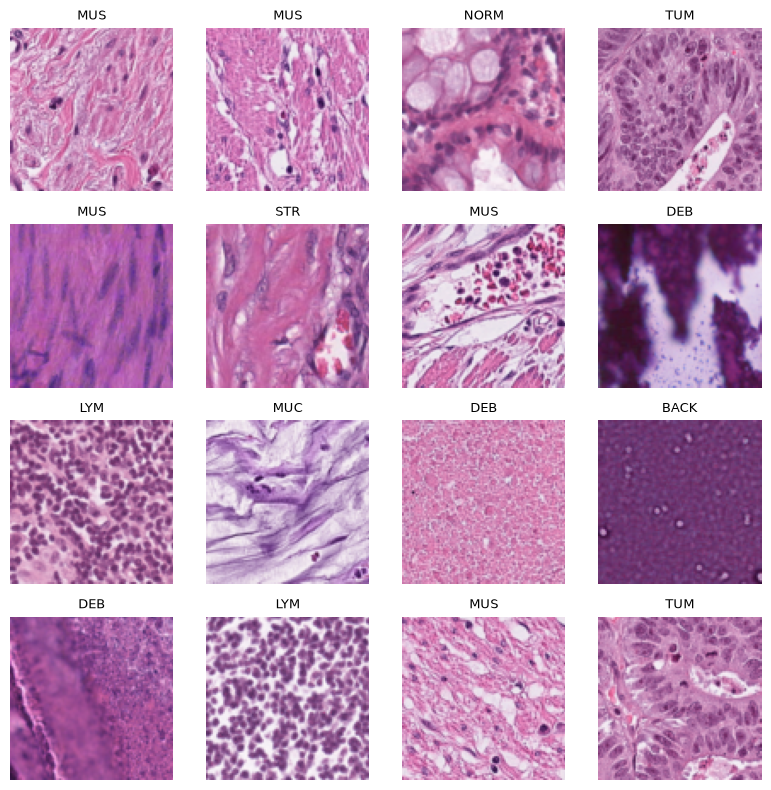

In [19]:
import torch
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

root = "../data/NCT-CRC-HE-100K"   # change this to your path

# 1. Transform: resize and convert the image to a tensor
tfm = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
])

# 2. Dataset: ImageFolder reads class names from the folder names
dataset = datasets.ImageFolder(root, transform=tfm)
print("Total images:", len(dataset))
print("Classes:", dataset.classes)

# 3. DataLoader: gives us batches of 16 shuffled images
loader = DataLoader(dataset, batch_size=16, shuffle=True)

# 4. Take just one batch
images, labels = next(iter(loader))
print("Batch shape:", images.shape)      # expect [16, 3, 96, 96]

# 5. Plot a 4x4 grid
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for ax, img, lab in zip(axes.flat, images, labels):
    ax.imshow(img.permute(1, 2, 0))      # [C,H,W] -> [H,W,C] for matplotlib
    ax.set_title(dataset.classes[lab], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("../results/figures/batch_grid.png", dpi=150)
plt.show()

ADI 10407
BACK 10566
DEB 11512
LYM 11557
MUC 8896
MUS 13536
NORM 8763
STR 10446
TUM 14317


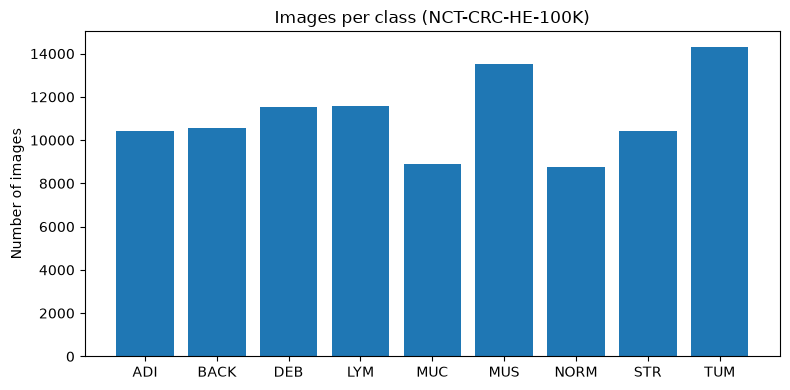

In [12]:
from collections import Counter 
import matplotlib.pyplot as plt
from torchvision import datasets

root = "../data/NCT-CRC-HE-100K"
ds = datasets.ImageFolder(root)

counts = Counter(ds.targets)
names = [ds.classes[i] for i in range(len(ds.classes))]
values = [counts[i] for i in range(len(ds.classes))]

for n,v in zip(names,values):
    print(n,v)
plt.figure(figsize=(8,4))
plt.bar(names,values)
plt.title("Images per class (NCT-CRC-HE-100K)")
plt.ylabel("Number of images")
plt.tight_layout()
plt.savefig("../results/figures/class_counts.png",dpi=150)
plt.show()

In [15]:
counts

Counter({8: 14317,
         5: 13536,
         3: 11557,
         2: 11512,
         1: 10566,
         7: 10446,
         0: 10407,
         4: 8896,
         6: 8763})

In [16]:
ds.classes

['ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM']

In [24]:
ds.classes[8]

'TUM'

In [28]:
ds.samples   # contain path of every images and labels i guess
# in the form of list of tuples

[('../data/NCT-CRC-HE-100K/ADI/ADI-AAAMHQMK.tif', 0),
 ('../data/NCT-CRC-HE-100K/ADI/ADI-AACCGLYD.tif', 0),
 ('../data/NCT-CRC-HE-100K/ADI/ADI-AACVGRFT.tif', 0),
 ('../data/NCT-CRC-HE-100K/ADI/ADI-AADGNDRG.tif', 0),
 ('../data/NCT-CRC-HE-100K/ADI/ADI-AAEKWPVP.tif', 0),
 ('../data/NCT-CRC-HE-100K/ADI/ADI-AAGDEQEK.tif', 0),
 ('../data/NCT-CRC-HE-100K/ADI/ADI-AAGQKKEG.tif', 0),
 ('../data/NCT-CRC-HE-100K/ADI/ADI-AAGSEPQK.tif', 0),
 ('../data/NCT-CRC-HE-100K/ADI/ADI-AAHTSYCW.tif', 0),
 ('../data/NCT-CRC-HE-100K/ADI/ADI-AAIRWEHA.tif', 0),
 ('../data/NCT-CRC-HE-100K/ADI/ADI-AAKARNMS.tif', 0),
 ('../data/NCT-CRC-HE-100K/ADI/ADI-AAKECYFG.tif', 0),
 ('../data/NCT-CRC-HE-100K/ADI/ADI-AAKMYPEI.tif', 0),
 ('../data/NCT-CRC-HE-100K/ADI/ADI-AAKNYETA.tif', 0),
 ('../data/NCT-CRC-HE-100K/ADI/ADI-AAKPCSCF.tif', 0),
 ('../data/NCT-CRC-HE-100K/ADI/ADI-AALISVWI.tif', 0),
 ('../data/NCT-CRC-HE-100K/ADI/ADI-AALYMMMY.tif', 0),
 ('../data/NCT-CRC-HE-100K/ADI/ADI-AANCAVPI.tif', 0),
 ('../data/NCT-CRC-HE-100K/A

In [27]:
ds.samples[89898]

('../data/NCT-CRC-HE-100K/TUM/TUM-GYYTPGGT.tif', 8)

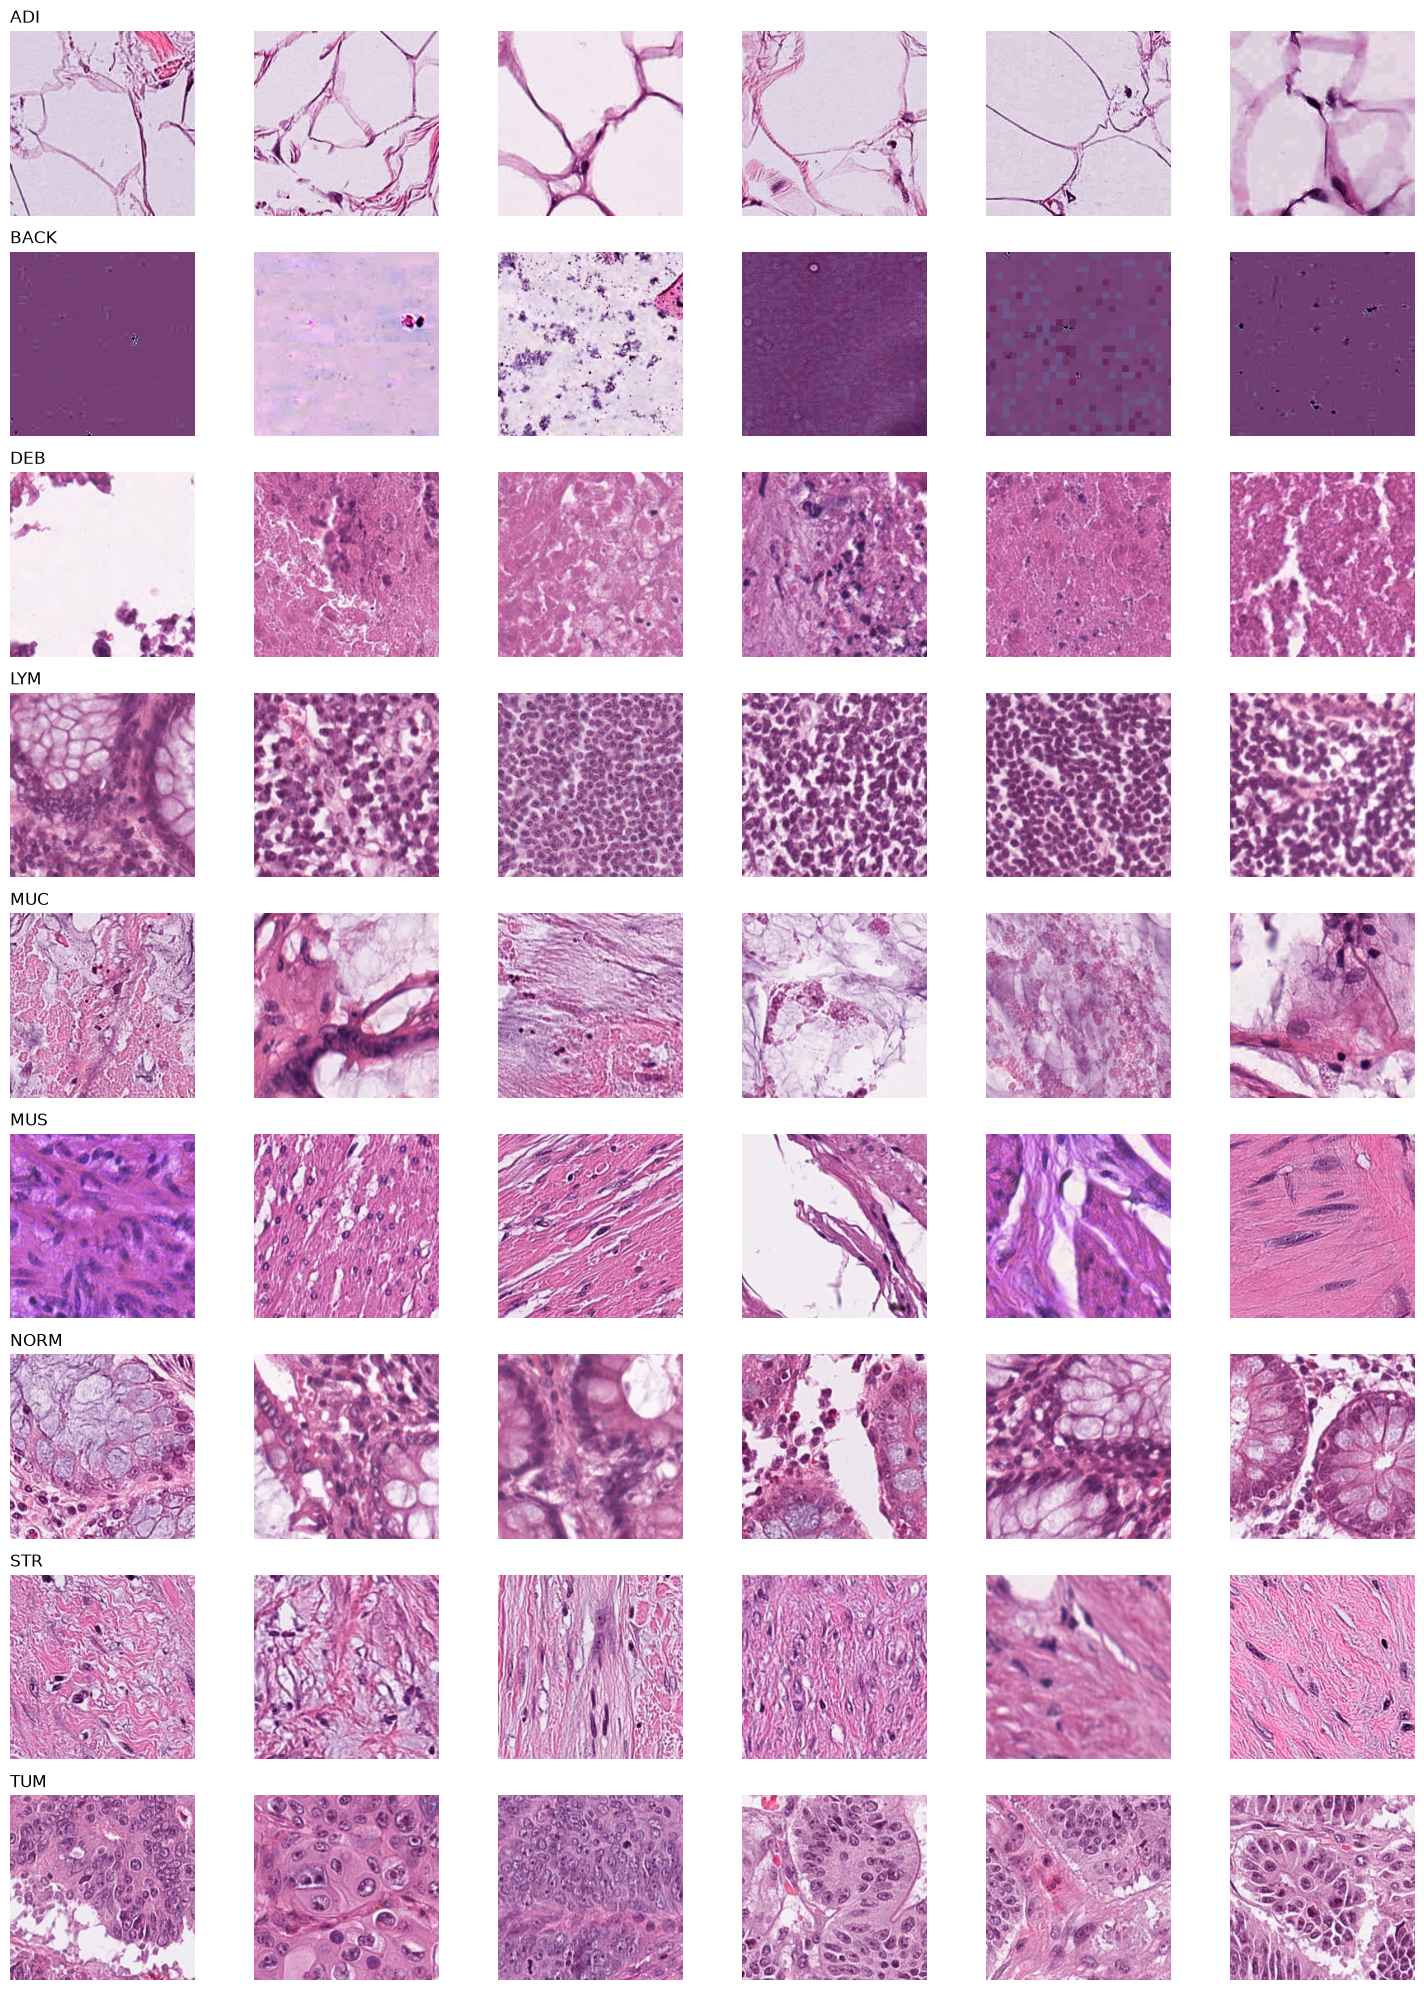

Sizes: {(224, 224)}
Modes: {'RGB'}


In [61]:
import random
from collections import defaultdict
from torchvision import datasets
import matplotlib.pyplot as plt
from PIL import Image

random.seed(0)                       # same images every run

ds = datasets.ImageFolder("../data/NCT-CRC-HE-100K")

# group image paths by class in a single pass
by_class = defaultdict(list)
for path, label in ds.samples:
    by_class[label].append(path)

# 9 rows (classes) x 6 columns (random examples)
fig, axes = plt.subplots(9, 6, figsize=(15, 20))
for i, name in enumerate(ds.classes):
    chosen = random.sample(by_class[i], 6)
    axes[i, 0].set_title(name, loc="left", fontsize=12)
    for j, path in enumerate(chosen):
        axes[i, j].imshow(Image.open(path))
        axes[i, j].axis("off")

plt.tight_layout()
plt.savefig("../results/figures/class_examples.png", dpi=150)
plt.show()

# Task 4: check image size and mode on 200 random images
sample = random.sample(ds.samples, 200)
sizes = {Image.open(p).size for p, _ in sample}
modes = {Image.open(p).mode for p, _ in sample}
print("Sizes:", sizes)    # expect {(224, 224)}
print("Modes:", modes)    # expect {'RGB'}